# Exploratory Data Analysis of Swedish Municipal Voter Turnout

This notebook explores municipality-level voter turnout and its relationships
with socioeconomic and demographic characteristics across the Swedish Riksdag
elections of 2014, 2018 and 2022.

The analysis focuses on:

- variation in municipal voter turnout across elections,
- persistence of turnout between consecutive elections,
- bivariate relationships between turnout and the selected predictors,
- changes in these relationships across elections,
- correlations among predictors,
- potential multicollinearity among modelling variables.

The analysis is descriptive and does not imply causal relationships.

In [1]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
# Load the processed historical modelling dataset.

master_df = pd.read_csv(
    "../data/processed/master_model_dataset_2014_2022.csv",
    dtype={"municipality_code": str}
)

In [3]:
# Inspect the structure of the dataset.

print("Shape:", master_df.shape)
print("Unique municipalities:", master_df["municipality_code"].nunique())

print("\nRows per election:")
print(
    master_df["election_year"]
    .value_counts()
    .sort_index()
)

master_df.head()

Shape: (870, 12)
Unique municipalities: 290

Rows per election:
election_year
2014    290
2018    290
2022    290
Name: count, dtype: int64


,municipality_code,municipality_name,election_year,predictor_year,turnout_pct,previous_turnout_pct,median_income_ksek,registered_unemployed_pct,higher_education_pct,average_age,population_density,log_population_density
0,0114,Upplands Väsby,2014,2012,84.1,83.2,475.3,12.0,35.591685,39.4,542.3,6.295819
1,0114,Upplands Väsby,2018,2016,84.7,84.1,528.9,11.9,38.783135,39.4,585.1,6.371783
2,0114,Upplands Väsby,2022,2020,79.5,84.7,525.5,15.9,42.504525,39.4,629.1,6.444290
3,0115,Vallentuna,2014,2012,89.3,87.6,609.5,6.8,41.632080,37.8,87.1,4.467057
4,0115,Vallentuna,2018,2016,90.0,89.3,676.5,6.1,44.404442,38.6,91.6,4.517431


## 2. Distribution of Municipal Voter Turnout

Turnout is first summarized separately for each election to examine changes
in the level and dispersion of municipal voter turnout over time.

Because every municipality contributes one observation to each election,
these statistics describe the distribution across Sweden's 290 municipalities.
They are not population-weighted national turnout estimates.

In [4]:
# Summarize municipal turnout separately for each election.

turnout_summary = (
    master_df
    .groupby("election_year")["turnout_pct"]
    .agg(
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    .round(2)
)

turnout_summary

,mean,median,std,min,max
election_year,,,,,
2014,85.86,85.90,2.52,70.4,92.9
2018,87.18,87.40,2.54,72.8,93.9
2022,84.84,85.05,3.10,69.1,92.4


### Initial observation

Mean municipal turnout increased from about 85.9% in 2014 to 87.2% in 2018,
before declining to about 84.8% in 2022.

The standard deviation was also somewhat larger in 2022, suggesting greater
variation in turnout across municipalities.

These values describe the average municipality and should not be interpreted
as Sweden's population-weighted national turnout.

In [5]:
# Identify the municipalities with the lowest and highest turnout
# in each election.

lowest_idx = (
    master_df
    .groupby("election_year")["turnout_pct"]
    .idxmin()
)

highest_idx = (
    master_df
    .groupby("election_year")["turnout_pct"]
    .idxmax()
)

turnout_extremes = pd.concat(
    [
        master_df.loc[
            lowest_idx,
            ["election_year", "municipality_name", "turnout_pct"]
        ].assign(position="Lowest"),
        
        master_df.loc[
            highest_idx,
            ["election_year", "municipality_name", "turnout_pct"]
        ].assign(position="Highest")
    ]
).sort_values(
    ["election_year", "position"]
)

turnout_extremes

,election_year,municipality_name,turnout_pct,position
309,2014,Lomma,92.9,Highest
864,2014,Haparanda,70.4,Lowest
310,2018,Lomma,93.9,Highest
865,2018,Haparanda,72.8,Lowest
311,2022,Lomma,92.4,Highest
866,2022,Haparanda,69.1,Lowest


## 3. Persistence of Municipal Voter Turnout

Previous-election turnout is the most important benchmark for the forecasting
study.

If municipalities with high turnout in one election also tend to have high
turnout in the next election, previous turnout should provide a strong
baseline against which the socioeconomic and machine-learning models must
be compared.

In [6]:
# Pooled correlation between previous-election and current turnout.

previous_turnout_corr = master_df[
    "previous_turnout_pct"
].corr(
    master_df["turnout_pct"]
)

print(
    "Pooled correlation:",
    round(previous_turnout_corr, 3)
)

Pooled correlation: 0.75


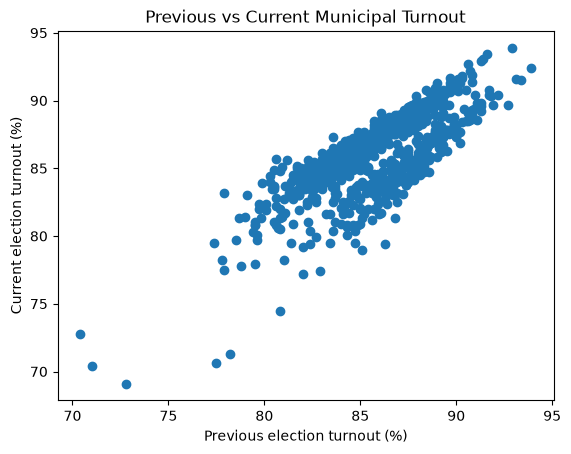

In [7]:
# Visualize the relationship between previous and current
# municipality turnout across all historical observations.

plt.scatter(
    master_df["previous_turnout_pct"],
    master_df["turnout_pct"]
)

plt.xlabel("Previous election turnout (%)")
plt.ylabel("Current election turnout (%)")
plt.title("Previous vs Current Municipal Turnout")
plt.show()

In [8]:
# Calculate the previous-turnout correlation separately
# for each election.

for year in sorted(master_df["election_year"].unique()):
    
    subset = master_df[
        master_df["election_year"] == year
    ]
    
    r = subset["previous_turnout_pct"].corr(
        subset["turnout_pct"]
    )
    
    print(year, round(r, 3))

2014 0.93
2018 0.966
2022 0.94


### Interpretation

Municipal turnout shows strong persistence between consecutive elections.

Within-election correlations between previous and current turnout are above
0.90 in all three elections. This indicates that municipalities with
relatively high turnout tend to remain high-turnout municipalities in the
following election.

This provides a strong justification for using previous-election turnout as
the historical baseline in the predictive analysis.

## 4. Higher Education and Voter Turnout

Higher education is examined as a socioeconomic characteristic potentially
associated with municipal voter turnout.

The analysis first considers the pooled relationship across all elections and
then calculates the correlation separately for 2014, 2018 and 2022.

These are municipality-level associations and should not be interpreted as
individual-level or causal effects.

In [9]:
# Pooled correlation between higher education and turnout.

higher_ed_corr = master_df[
    "higher_education_pct"
].corr(
    master_df["turnout_pct"]
)

print(
    "Pooled correlation:",
    round(higher_ed_corr, 3)
)

Pooled correlation: 0.359


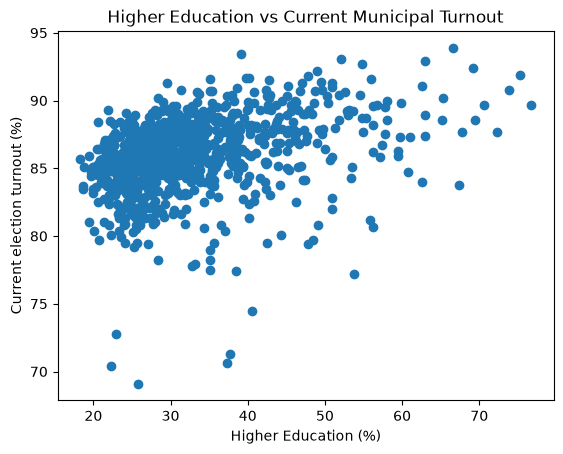

In [10]:
# Visualize the pooled relationship between higher education and turnout.

plt.scatter(
    master_df["higher_education_pct"],
    master_df["turnout_pct"]
)
plt.xlabel("Higher Education (%)")
plt.ylabel("Current election turnout (%)")
plt.title("Higher Education vs Current Municipal Turnout")
plt.show()

In [11]:
# Calculate the correlation separately for each election.

for year in sorted(master_df["election_year"].unique()):

    subset = master_df[
        master_df["election_year"] == year
    ]

    r = subset["higher_education_pct"].corr(
        subset["turnout_pct"]
    )

    print(year, round(r, 3))

2014 0.446
2018 0.482
2022 0.334


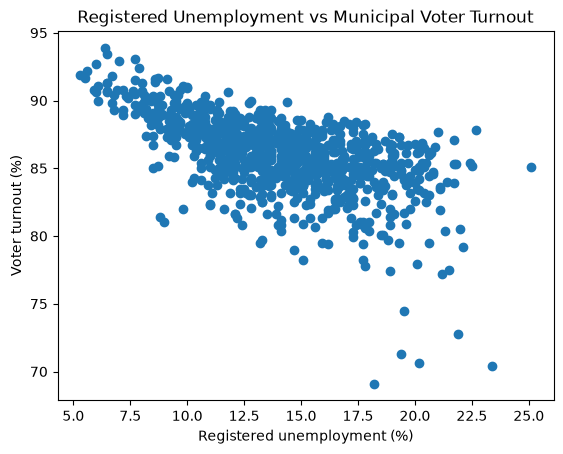

In [12]:
plt.scatter(
    master_df["registered_unemployed_pct"],
    master_df["turnout_pct"]
)

plt.xlabel("Registered unemployment (%)")
plt.ylabel("Voter turnout (%)")
plt.title("Registered Unemployment vs Municipal Voter Turnout")
plt.show()

### Interpretation

Higher education is positively associated with municipal voter turnout in
all three elections.

The relationship is strongest in 2018 and somewhat weaker in 2022.
However, these correlations are descriptive and do not establish that higher
education causes higher turnout.

## 5. Registered Unemployment and Voter Turnout

Registered unemployment is examined as a socioeconomic indicator that may be
associated with differences in turnout across municipalities.

As above, both pooled and election-specific relationships are examined.

In [13]:
# Pooled correlation between unemployment and turnout.

unemployment_corr = master_df[
    "registered_unemployed_pct"
].corr(
    master_df["turnout_pct"]
)

print(
    "Pooled correlation:",
    round(unemployment_corr, 3)
)

Pooled correlation: -0.593


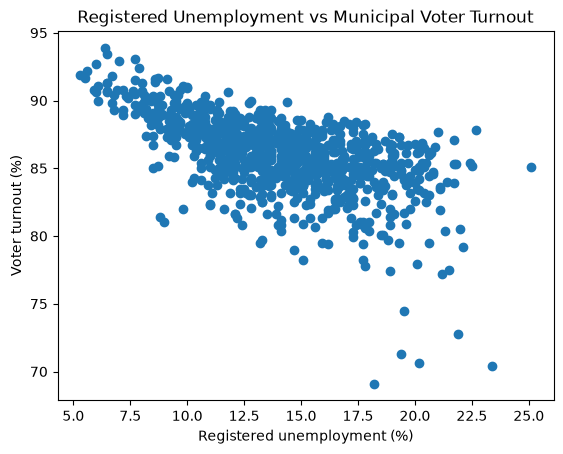

In [14]:
# Pooled correlation between unemployment and turnout.
plt.scatter(
    master_df["registered_unemployed_pct"],
    master_df["turnout_pct"]
)

plt.xlabel("Registered unemployment (%)")
plt.ylabel("Voter turnout (%)")
plt.title("Registered Unemployment vs Municipal Voter Turnout")
plt.show()

In [15]:
# Calculate the unemployment-turnout correlation separately
# for each election.
for year in sorted(master_df["election_year"].unique()):

    subset = master_df[
        master_df["election_year"] == year
    ]

    r = subset["registered_unemployed_pct"].corr(
        subset["turnout_pct"]
    )

    print(year, round(r, 3))

2014 -0.58
2018 -0.64
2022 -0.659


### Interpretation

Registered unemployment shows a moderately strong negative association with
municipal voter turnout.

Municipalities with higher registered unemployment tended to have lower
turnout, and this negative relationship appears in all three elections.

This is an ecological association and should not be interpreted as evidence
that an unemployed individual is necessarily less likely to vote.

## 6. Median Household Income and Voter Turnout

Median disposable household income is examined as another indicator of
municipal socioeconomic conditions.

The analysis compares the pooled association with election-specific
correlations to determine whether the relationship is reasonably consistent
over time.

In [16]:
# Pooled correlation between median income and turnout.

income_corr = master_df[
    "median_income_ksek"
].corr(
    master_df["turnout_pct"]
)

print(
    "Pooled correlation:",
    round(income_corr, 3)
)

Pooled correlation: 0.48


In [17]:

# Calculate the income-turnout correlation separately
# for each election.
for year in sorted(master_df["election_year"].unique()):

    subset = master_df[
        master_df["election_year"] == year
    ]

    r = subset["median_income_ksek"].corr(
        subset["turnout_pct"]
    )

    print(year, round(r, 3))

2014 0.582
2018 0.581
2022 0.467


### Interpretation

Median household income is positively associated with municipal voter turnout
in all three elections.

The relationship is moderately strong in 2014 and 2018 and somewhat weaker
in 2022. As with the other predictors, this is a descriptive municipality-level
association rather than evidence of a causal effect.

## 7. Average Age and Voter Turnout

Average municipal age is examined as a demographic characteristic associated
with differences in voter turnout.

Both the pooled relationship and election-specific correlations are examined.
Because the analysis is conducted at the municipality level, the results
should not be interpreted as describing individual voting behaviour.

In [18]:
# Pooled correlation between average age and voter turnout.

age_corr = master_df[
    "average_age"
].corr(
    master_df["turnout_pct"]
)

print(
    "Pooled correlation:",
    round(age_corr, 3)
)

Pooled correlation: -0.177


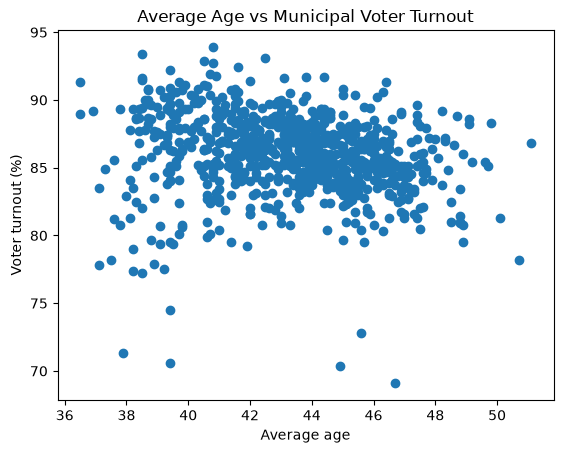

In [19]:
# Visualize the pooled relationship between average age and turnout.
plt.scatter(
    master_df["average_age"],
    master_df["turnout_pct"]
)

plt.xlabel("Average age")
plt.ylabel("Voter turnout (%)")
plt.title("Average Age vs Municipal Voter Turnout")
plt.show()

In [20]:
# Calculate the age-turnout correlation separately for each election.
for year in sorted(master_df["election_year"].unique()):

    subset = master_df[
        master_df["election_year"] == year
    ]

    r = subset["average_age"].corr(
        subset["turnout_pct"]
    )

    print(year, round(r, 3))

2014 -0.283
2018 -0.248
2022 -0.021


### Interpretation

Average municipal age shows a weak negative association with voter turnout.

The relationship is more noticeable in 2014 (`r = -0.283`) and 2018
(`r = -0.248`), but is almost absent in 2022 (`r = -0.021`).

This suggests that the bivariate relationship between municipal age structure
and turnout is not stable across elections. Because the analysis is conducted
at the municipality level, this should not be interpreted as evidence about
the voting behaviour of individual older or younger citizens.

## 8. Population Density and Voter Turnout

Population density is strongly right-skewed across Swedish municipalities.
Therefore, the log-transformed population-density variable prepared in the
data-preparation notebook is used in this analysis.

Both the pooled relationship and election-specific correlations are examined.
The log-transformed variable is also used later in the statistical and
predictive models.

In [21]:
# Calculate the pooled correlation between log population density
# and municipal voter turnout.

density_corr = master_df[
    "log_population_density"
].corr(
    master_df["turnout_pct"]
)

print(
    "Pooled correlation:",
    round(density_corr, 3)
)

Pooled correlation: 0.21


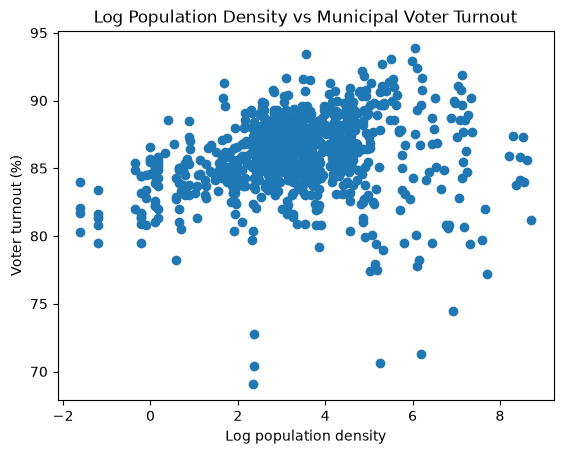

In [22]:
# Visualize the pooled relationship between log population density
# and municipal voter turnout.

plt.scatter(
    master_df["log_population_density"],
    master_df["turnout_pct"]
)

plt.xlabel("Log population density")
plt.ylabel("Voter turnout (%)")
plt.title("Log Population Density vs Municipal Voter Turnout")
plt.show()

In [23]:
# Calculate the density-turnout correlation separately
# for each election.
for year in sorted(master_df["election_year"].unique()):

    subset = master_df[
        master_df["election_year"] == year
    ]

    r = subset["log_population_density"].corr(
        subset["turnout_pct"]
    )

    print(year, round(r, 3))

2014 0.29
2018 0.307
2022 0.106


### Interpretation

Log population density shows a weak positive association with municipal voter
turnout.

The relationship is somewhat stronger in 2014 and 2018 but becomes much
weaker in 2022. This suggests that the association between municipal density
and turnout also varies across elections.

As with the other predictors, this is a descriptive municipality-level
association rather than evidence of a causal effect.

## 9. Relationships Among Predictors

The modelling variables may also be correlated with one another.

Examining predictor correlations is important because strong relationships
between predictors can make individual regression coefficients harder to
interpret and may lead to multicollinearity.

The same six predictor variables used in the later modelling analysis are
examined here.

In [24]:
# Define the predictor variables used in the statistical
# and machine-learning models.

predictor_cols = [
    "previous_turnout_pct",
    "median_income_ksek",
    "registered_unemployed_pct",
    "higher_education_pct",
    "average_age",
    "log_population_density"
]

correlation_matrix = master_df[predictor_cols].corr()

correlation_matrix

,previous_turnout_pct,median_income_ksek,registered_unemployed_pct,higher_education_pct,average_age,log_population_density
previous_turnout_pct,1.000000,0.625573,-0.565597,0.516843,-0.238791,0.313592
median_income_ksek,0.625573,1.000000,-0.692526,0.699763,-0.587340,0.587750
registered_unemployed_pct,-0.565597,-0.692526,1.000000,-0.468119,0.287892,-0.265878
higher_education_pct,0.516843,0.699763,-0.468119,1.000000,-0.638920,0.686224
average_age,-0.238791,-0.587340,0.287892,-0.638920,1.000000,-0.704878
log_population_density,0.313592,0.587750,-0.265878,0.686224,-0.704878,1.000000


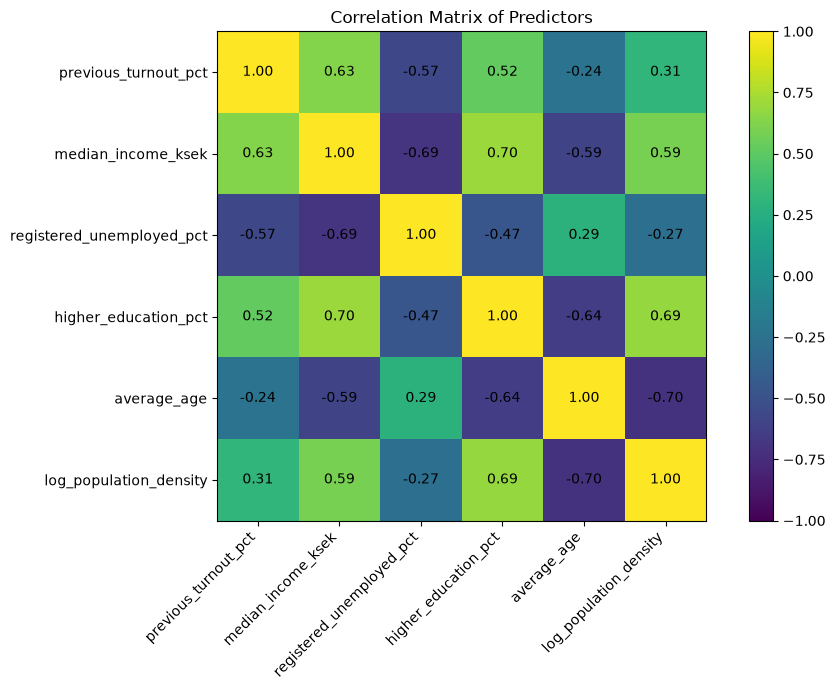

In [25]:
# Visualize correlations among the predictor variables.


fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(predictor_cols)))
ax.set_yticks(range(len(predictor_cols)))

ax.set_xticklabels(predictor_cols, rotation=45, ha="right")
ax.set_yticklabels(predictor_cols)

for i in range(len(predictor_cols)):
    for j in range(len(predictor_cols)):
        ax.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(im)
plt.title("Correlation Matrix of Predictors")
plt.tight_layout()
plt.show()

### Interpretation

Some predictors are moderately to strongly correlated. In particular, median
income is positively related to higher education, while average age is
negatively related to log population density.

These relationships do not necessarily require removing variables, but they
motivate a formal multicollinearity check using the Variance Inflation Factor
(VIF).

## 10. Multicollinearity Check

Variance Inflation Factors (VIFs) are calculated to assess whether correlations
among predictors are large enough to create serious multicollinearity problems.

Higher VIF values indicate that a predictor can be substantially explained by
the other predictors. As a practical guideline, values below about 5 generally
do not indicate severe multicollinearity.

In [26]:
# Create a copy containing only the modelling predictors.

X_vif = master_df[
    predictor_cols
].copy()


# Add an intercept because VIF is calculated from auxiliary
# regression models.

X_vif = sm.add_constant(X_vif)


# Calculate VIF for every predictor.

vif_df = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif.values,
            i
        )
        for i in range(X_vif.shape[1])
    ]
})


# Remove the intercept from the final table and
# show predictors from highest to lowest VIF.

vif_df = (
    vif_df[
        vif_df["variable"] != "const"
    ]
    .sort_values(
        "VIF",
        ascending=False
    )
)

vif_df.round(2)

,variable,VIF
2,median_income_ksek,3.80
4,higher_education_pct,2.81
6,log_population_density,2.56
5,average_age,2.40
3,registered_unemployed_pct,2.16
1,previous_turnout_pct,1.90


### Interpretation

All predictor VIF values are below 5, suggesting that severe
multicollinearity is not present in the selected modelling variables.

Median household income has the highest VIF, which is consistent with its
correlation with higher education, but the value remains within an acceptable
range.

Therefore, all six predictors are retained for the subsequent statistical and
predictive analyses.

## EDA Summary

The exploratory analysis shows substantial persistence in municipal voter
turnout across elections, making previous-election turnout an important
forecasting benchmark.

Among the socioeconomic variables, registered unemployment shows the strongest
negative bivariate relationship with turnout, while higher education and median
income show positive associations. Average age and log population density have
weaker and less stable relationships across elections.

Several predictors are correlated with one another, but the VIF analysis does
not indicate severe multicollinearity. These exploratory findings motivate the
multivariable statistical analysis in the next notebook.